In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

KeyboardInterrupt: 

In [ ]:
df = pd.read_excel('datasets/EMR_analysis_cleaned_&_merged.xlsx')

In [ ]:
#preview the dataframe
df.head()

,action_plan_emr,age,alternative_power_outage,capacity_decision_making,clinic_name_department,commitment_emr_mission,confidence_using_system,data_collection_appreciation,data_collection_burden,data_collection_monitoring,...,poor_leadership,profesion,regular_feedback_report,regular_meetings_emr_utilization,regular_monitoring_evaluation_supervisor,sex,technical_support_time,tediousness_emr_data_collection,timely_completion_emr_tasks,used_emr_decision_making
0,yes,1967,Manual paper register,yes,FMC Ebute metta,3.0,4.0,4.0,2.0,2.0,...,NaN,Doctor,yes,yes,yes,Male,within 24 hours,2.0,3.0,yes
1,yes,25,Generator,yes,Not in a clinic,4.0,5.0,5.0,2.0,5.0,...,NaN,other please specify,no,yes,yes,Female,within 24 hours,2.0,5.0,yes
2,yes,34,Generator,yes,PICU,4.0,4.0,3.0,2.0,0.0,...,NaN,Nurse,no,yes,yes,Female,within 24 hours,1.0,4.0,no
3,yes,37,UPS | Manual paper register,no,Immunisation/family planning clinic,5.0,5.0,5.0,1.0,5.0,...,NaN,Nurse,yes,yes,yes,Female,within 24 hours,1.0,5.0,no
4,yes,24,Manual paper register,yes,Specialist Clinic 2,5.0,1.0,5.0,1.0,2.0,...,NaN,other please specify | Health Record Technici...,yes,yes,yes,Female,within 24 hours,1.0,5.0,yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 44 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   action_plan_emr                           166 non-null    object 
 1   age                                       167 non-null    object 
 2   alternative_power_outage                  165 non-null    object 
 3   capacity_decision_making                  161 non-null    object 
 4   clinic_name_department                    152 non-null    object 
 5   commitment_emr_mission                    166 non-null    float64
 6   confidence_using_system                   167 non-null    float64
 7   data_collection_appreciation              166 non-null    float64
 8   data_collection_burden                    166 non-null    float64
 9   data_collection_monitoring                165 non-null    float64
 10  database_version                      

In [ ]:
df.isnull().sum()

action_plan_emr                               3
age                                           2
alternative_power_outage                      4
capacity_decision_making                      8
clinic_name_department                       17
commitment_emr_mission                        3
confidence_using_system                       2
data_collection_appreciation                  3
data_collection_burden                        3
data_collection_monitoring                    4
database_version                             69
designated_person_ehis_reports                1
designated_person_patient_data                1
education                                     2
emr_designated_computer                       3
emr_is_complex                                6
emr_online_offline                            4
emr_performance_monitoring                    2
emr_software_rating                           0
financial_resources                          18
good_system_functions_integration       

# Grouping the variables(columns) into the 3 categories

In [ ]:
technical_determinants = df[[
    'emr_software_rating',
    'network_connectivity_challenge',
    'technical_support_time',
    'timely_completion_emr_tasks',
    'emr_is_complex',
    'good_system_functions_integration',
    'emr_online_offline',
    'database_version',
    'emr_designated_computer',
    'alternative_power_outage',
    'patient_registration_method'
]].copy()

behavioural_determinants = df[[
    'confidence_using_system',
    'data_collection_burden',
    'tediousness_emr_data_collection',
    'commitment_emr_mission',
    'likely_to_use_emr',
    'age',
    'education',
    'profesion',
    'sex',
    'data_collection_appreciation',
    'meaningful_data_collection',
    'need_technical_support',
    'used_emr_decision_making',
    'emr_is_complex'
]].copy()

environmental_determinants = df[[
    'financial_resources',
    'regular_meetings_emr_utilization',
    'health_information_policies',
    'organizational_rules',
    'poor_leadership',
    'action_plan_emr',
    'capacity_decision_making',
    'clinic_name_department',
    'designated_person_ehis_reports',
    'designated_person_patient_data',
    'emr_performance_monitoring',
    'hprs_training_last_12_months',
    'hprs_training_provider',
    'hprs_training_topic',
    'inadequate_human_resources',
    'organizational_practices',
    'orientation_emr_utilization',
    'regular_feedback_report',
    'regular_monitoring_evaluation_supervisor'
]].copy()

# Analysis on the technical determinants

In [ ]:
technical_determinants.head(50)

,emr_software_rating,network_connectivity_challenge,technical_support_time,timely_completion_emr_tasks,emr_is_complex,good_system_functions_integration,emr_online_offline,database_version,emr_designated_computer,alternative_power_outage,patient_registration_method
0,Easy to use,sometimes,within 24 hours,3.0,1.0,4.0,Online,Unknown,Yes,Manual paper register,Both
1,Easy to use,Most of the time,within 24 hours,5.0,2.0,5.0,Online,A database version refers to a specific iterat...,Yes,Generator,EHIS
2,Easy to use,sometimes,within 24 hours,4.0,1.0,4.0,Online,An update of a database management system with...,Yes,Generator,Both
3,Easy to use,sometimes,within 24 hours,5.0,1.0,5.0,Online | Offline,Information system,Yes,UPS | Manual paper register,EHIS
4,Easy to use,Most of the time,within 24 hours,5.0,1.0,5.0,Online,V10.0,Yes,Manual paper register,EHIS
5,Easy to use,sometimes,within 24 hours,4.0,3.0,4.0,Online,Largest,Yes,Manual paper register,Both
6,Easy to use,sometimes,within 24 hours,5.0,1.0,5.0,Online,10.1,Yes,Generator | UPS,EHIS
7,Easy to use,sometimes,within 24 hours,5.0,5.0,5.0,Online,10.1,Yes,Generator,EHIS
8,Easy to use,Most of the time,1-7days,4.0,1.0,2.0,Online,Lab top,Yes,UPS,NaN
9,Easy to use,sometimes,within 24 hours,4.0,1.0,5.0,Online,Not sure,Yes,Generator | Manual paper register,EHIS


In [ ]:
technical_determinants.describe()

,timely_completion_emr_tasks,emr_is_complex,good_system_functions_integration
count,166.000000,163.00000,166.000000
mean,3.656627,2.03681,3.819277
std,0.964295,1.15411,0.980347
min,1.000000,1.00000,1.000000
25%,3.000000,1.00000,3.250000
50%,4.000000,2.00000,4.000000
75%,4.000000,2.00000,4.000000
max,5.000000,5.00000,5.000000


In [ ]:
technical_determinants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   emr_software_rating                169 non-null    object 
 1   network_connectivity_challenge     169 non-null    object 
 2   technical_support_time             166 non-null    object 
 3   timely_completion_emr_tasks        166 non-null    float64
 4   emr_is_complex                     163 non-null    float64
 5   good_system_functions_integration  166 non-null    float64
 6   emr_online_offline                 165 non-null    object 
 7   database_version                   100 non-null    object 
 8   emr_designated_computer            166 non-null    object 
 9   alternative_power_outage           165 non-null    object 
 10  patient_registration_method        166 non-null    object 
dtypes: float64(3), object(8)
memory usage: 14.7+ KB


In [ ]:
technical_determinants['emr_designated_computer'].value_counts(dropna=False)

emr_designated_computer
Yes     84
YES     79
NaN      3
No       3
Name: count, dtype: int64

In [ ]:
technical_determinants['emr_designated_computer'].unique()

array(['YES ', nan, 'Yes', 'No'], dtype=object)

In [ ]:
technical_determinants['emr_designated_computer'] = technical_determinants['emr_designated_computer'].map({'YES ': 'Yes', 'NO': 'No', 'Yes': 'Yes', 'No': 'No', np.nan:'No'})

In [ ]:
technical_determinants['emr_designated_computer'].value_counts(dropna=False)

emr_designated_computer
Yes    163
No       6
Name: count, dtype: int64

In [ ]:
technical_determinants['emr_software_rating'].value_counts(dropna=False)


emr_software_rating
Easy to use               118
Moderate                   47
Moderate | Easy to use      2
Difficult to use            2
Name: count, dtype: int64

In [ ]:
technical_determinants['emr_software_rating'].unique()

array(['Easy to use', 'Moderate', 'Moderate | Easy to use',
       'Difficult to use'], dtype=object)

In [ ]:
emr_soft_rat = technical_determinants.groupby('emr_software_rating')['emr_is_complex'].value_counts().unstack().fillna(0)
emr_soft_rat

emr_is_complex,1.0,2.0,3.0,4.0,5.0
emr_software_rating,,,,,
Difficult to use,0.0,0.0,2.0,0.0,0.0
Easy to use,51.0,40.0,7.0,8.0,8.0
Moderate,11.0,21.0,6.0,6.0,1.0
Moderate | Easy to use,2.0,0.0,0.0,0.0,0.0


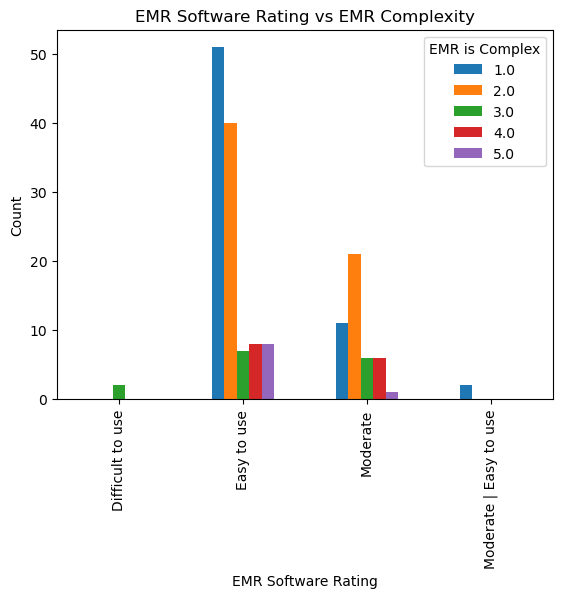

In [ ]:
emr_soft_rat.plot(kind='bar')
plt.title('EMR Software Rating vs EMR Complexity')
plt.xlabel('EMR Software Rating')
plt.ylabel('Count')
plt.legend(title='EMR is Complex', loc='upper right')
plt.show()

In [ ]:
technical_determinants['database_version'].unique()

array(['Unknown',
       'A database version refers to a specific iteration or release of a database management system (DBMS) or a particular database instance.',
       'An update of a database management system with new features, bug fixes and improvements.',
       'Information system', 'V10.0', 'Largest', '10.1', 'Lab top',
       'Not sure', 'Global hms',
       "It's a version number that Helps identify the specific state of a database, making it easier to manage, update or troubleshoot.",
       'No idea', 'Oracle', 'A database is where information is stored',
       'Cant specify', 'Not aware', 'Global view 4.0',
       'Globalcare. V.10.1', 'Not known', 'V.10.1', 'Software', 'EMR',
       'Globalcare v.10.1', "Don't know for sure", 'GLOBALCARE V 10.1',
       'Globalcare', 'Oracle SQL', '1',
       'Is there a specific iteration or release of a database management system',
       'Swift', "I don't know", '2.0', '3', 'Am not sure', '100, 000',
       'This is the detailed infor

In [ ]:
technical_determinants['database_version'].value_counts()

database_version
EMR                                                                                                                                       9
10.1                                                                                                                                      6
Global Care V.10.1                                                                                                                        5
I don't know                                                                                                                              4
No idea                                                                                                                                   4
                                                                                                                                         ..
3                                                                                                                                         1
Am 